# 06. Comms and hotel

The two fixed parts of the load: the **hotel** load (everything that's always on) and the extra power while **Starlink** is on. Both are read off MANUAL (motor off), then checked on the other modes. nb 07 and nb 08 lock them and fit only the motor on top.

1. Starlink on vs off: load by mode, load vs speed, first conclusions (hotel ≈ 10 W, Starlink ≈ 22 W)
2. Check: subtract both and see what's left

When Starlink is on (the session list) is in nb 05. Channels: battery1 = battery, battery2 ("thruster" in Tether) = total load.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (14, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("../data/scout_telemetry_2025-07.csv", na_values="null")
df["t"] = pd.to_datetime(df["created_at"], format="ISO8601", utc=True)
df = df.sort_values("t").reset_index(drop=True)
df["P_load"] = df.voltage_battery1_v * df.current_battery2_a     # W, total load

SL_COLORS = {False: "#ff7f0e", True: "#1f77b4"}
SL_NAMES = {False: "Starlink off", True: "Starlink on"}


## 1. Starlink on vs off

**Starlink on/off:** a moment counts as "Starlink on" if it falls inside a Starlink session (Starlink messages less than 2 min apart, plus 30 s either side). Everything else is "off".

**Load** comes over both links, so we can compare. "Off" minutes are all Iridium (the only link then); "on" minutes are mostly Starlink rows.

**One point per minute:** Starlink sends every 1 s on some days and 15 s on others, so raw rows would over-weight those days. Load and speed are averaged per minute; mode is the last one in the minute. All minutes are kept (armed and disarmed).

In [2]:
direct = df[df.communication_mode == "direct"]
session_id = (direct.t.diff() > pd.Timedelta("2min")).cumsum()
sessions = direct.groupby(session_id).t.agg(start="min", end="max").reset_index(drop=True)
pad = pd.Timedelta("30s")
df["starlink"] = False
for start, end in sessions.itertuples(index=False):
    df.loc[df.t.between(start - pad, end + pad), "starlink"] = True

m = (df.dropna(subset=["P_load"]).set_index("t").resample("1min")
       .agg({"P_load": "mean", "groundspeed_ms": "mean", "custom_mode": "last", "custom0_arming": "last", "starlink": "max"})
       .dropna(subset=["P_load"]).reset_index())
m["starlink"] = m.starlink.astype(bool)
m["armed"] = m.custom0_arming == 1

# MANUAL split by arming (disarmed = motor can't run at all); AUTO / mode 17 are armed except a minute or two
GROUP_NAMES = ["MANUAL disarmed", "MANUAL armed", "AUTO", "mode 17"]
GROUP_COLORS = {"MANUAL disarmed": "#c7c7c7", "MANUAL armed": "#7f7f7f", "AUTO": "#2ca02c", "mode 17": "#d62728"}
m["group"] = np.select([(m.custom_mode == 0) & ~m.armed, (m.custom_mode == 0) & m.armed, m.custom_mode == 10, m.custom_mode == 17],
                       GROUP_NAMES, default="other")
pd.crosstab(m.group, m.starlink.map(SL_NAMES), margins=True).reindex(GROUP_NAMES + ["other", "All"]).dropna(how="all")

starlink,Starlink off,Starlink on,All
group,,,
MANUAL disarmed,420.0,210.0,630.0
MANUAL armed,1737.0,666.0,2403.0
AUTO,431.0,1316.0,1747.0
mode 17,400.0,719.0,1119.0
All,2988.0,2911.0,5899.0


### Load by mode

Every minute as a dot (spread sideways so they don't stack), with a box for the middle 50% and a line at the median.

MANUAL is split by arming: **disarmed** (the motor can't run at all) and **armed** (motor allowed, but MANUAL with no stick input).


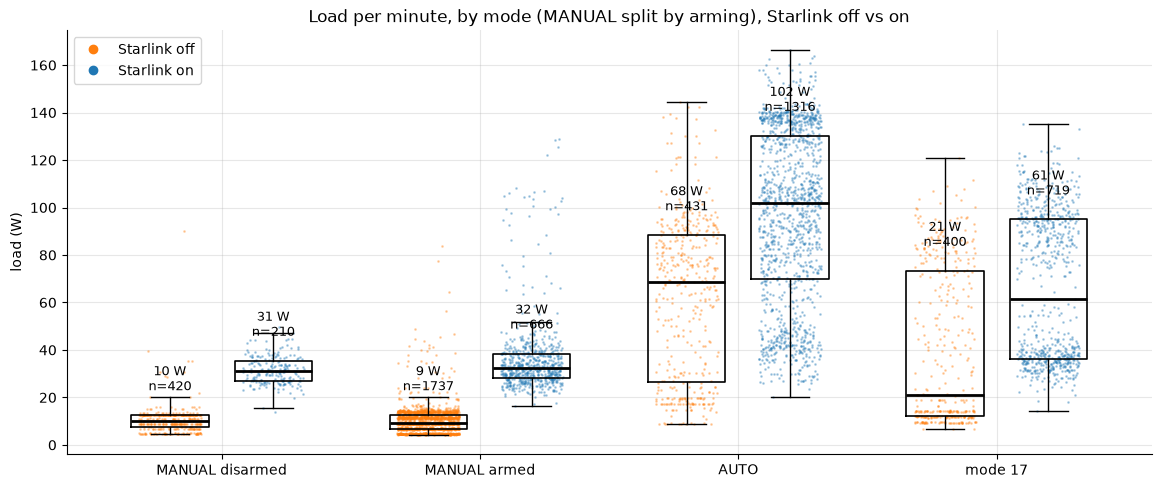

In [3]:
modes = [0, 10, 17]
fig, ax = plt.subplots(figsize=(14, 5.5))
rng = np.random.default_rng(0)
for i, grp in enumerate(GROUP_NAMES):
    for j, sl in enumerate([False, True]):
        y = m[(m.group == grp) & (m.starlink == sl)].P_load
        x = i + (j - 0.5) * 0.4
        ax.plot(x + rng.uniform(-0.12, 0.12, len(y)), y, ".", ms=2, alpha=0.3, color=SL_COLORS[sl])
        ax.boxplot(y, positions=[x], widths=0.3, showfliers=False, medianprops=dict(color="k", lw=2),
                   boxprops=dict(lw=1.2), whiskerprops=dict(lw=1), capprops=dict(lw=1))
        ax.annotate(f"{y.median():.0f} W\nn={len(y)}", (x, y.quantile(0.75)), xytext=(0, 18),
                    textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(range(len(GROUP_NAMES)), GROUP_NAMES)
ax.set_xlim(-0.6, len(GROUP_NAMES) - 0.4)
ax.set_ylabel("load (W)")
for sl in [False, True]:
    ax.plot([], [], "o", color=SL_COLORS[sl], label=SL_NAMES[sl])
ax.legend(loc="upper left")
ax.set_title("Load per minute, by mode (MANUAL split by arming), Starlink off vs on")
plt.show()

### Load vs speed, by mode

Same minutes, against speed over ground. Lines are the median per 0.2 m/s bin (bins centred on 0, 0.2, 0.4…, because Iridium reports speed in 0.2 m/s steps; only bins with ≥ 15 minutes). X axis cropped at 2.5 m/s.

MANUAL is split by arming: **disarmed** (the motor can't run at all) and **armed** (motor allowed, but MANUAL with no stick input).


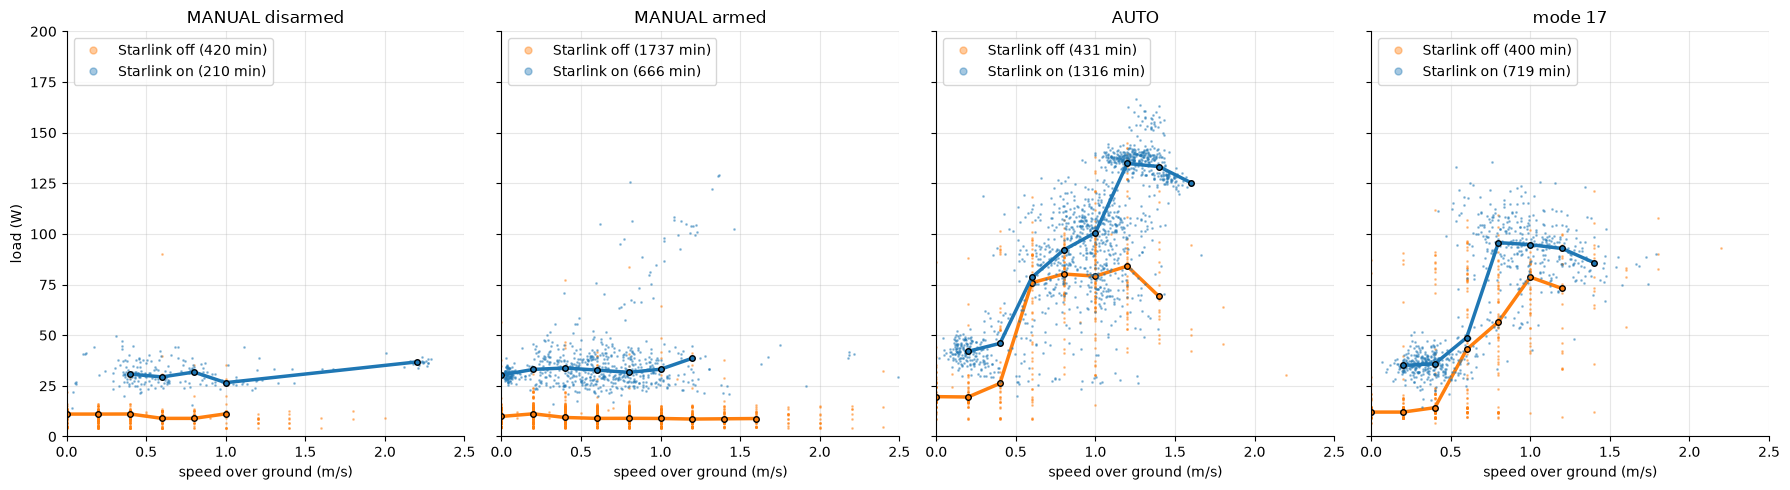

In [4]:
BINS = np.arange(-0.1, 2.61, 0.2)

def binned(d, min_n=15):
    g = d.groupby(pd.cut(d.groundspeed_ms, BINS), observed=False).P_load
    out = pd.DataFrame({"x": [b.mid for b in g.median().index], "median": g.median().values, "n": g.size().values})
    return out[out.n >= min_n]

fig, axes = plt.subplots(1, 4, figsize=(18, 5), sharey=True)
for ax, grp in zip(axes, GROUP_NAMES):
    d = m[m.group == grp]
    for sl in [False, True]:
        s = d[d.starlink == sl]
        ax.plot(s.groundspeed_ms, s.P_load, ".", ms=2, alpha=0.4, color=SL_COLORS[sl], label=f"{SL_NAMES[sl]} ({len(s)} min)")
        b = binned(s)
        ax.plot(b.x, b["median"], "-o", ms=4, lw=2.5, color=SL_COLORS[sl], mec="k")
    ax.set_title(grp); ax.set_xlabel("speed over ground (m/s)"); ax.set_xlim(0, 2.5)
    ax.legend(markerscale=5, loc="upper left")
axes[0].set_ylabel("load (W)"); axes[0].set_ylim(0, 200)
plt.tight_layout(); plt.show()

<div style="color:#c00000">

### First conclusions

- **MANUAL ≈ motor off.** Load in MANUAL doesn't change with speed, and armed MANUAL draws the same as disarmed (Iridium: 9.9 vs 11.0 W). The speed in MANUAL is drift.
- **Base hotel load ≈ 10 W** (MANUAL, Starlink off).
- **Starlink ≈ 22 W** while on (MANUAL, on minus off, flat at every speed).
- After subtracting both, MANUAL sits at ~0 W and the Starlink off/on curves overlap in mode 17, so the numbers seem to hold outside MANUAL too.

Caveats: the base moves between ~5 and 15 W over a day; anything that switches on together with Starlink is counted inside the 22 W; both numbers come from MANUAL only.

</div>

## 2. Check: propulsion power

If those numbers are right, removing them from the load should leave only the motor:

**propulsion = load − 10 W − 22 W × (Starlink on)**

Same plot as above. If the subtraction works, MANUAL should sit around 0 and the off/on curves should land on top of each other.

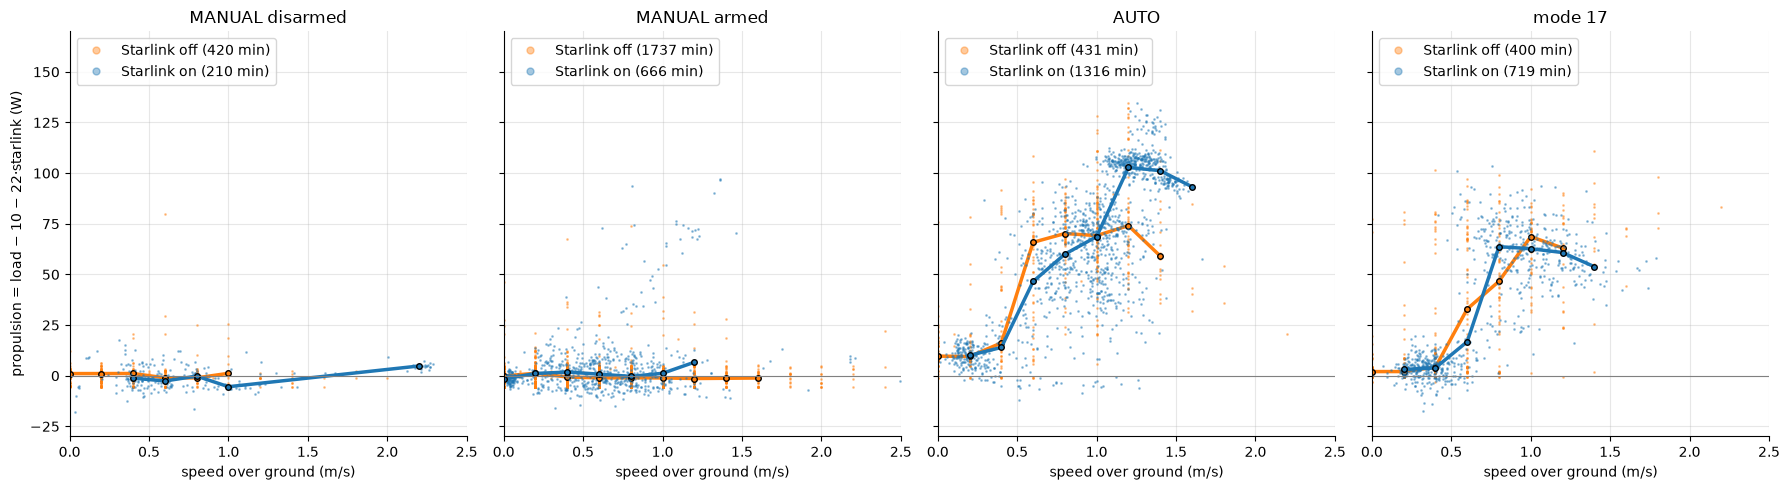

In [5]:
HOTEL_W, STARLINK_W = 10, 22
m["P_prop"] = m.P_load - HOTEL_W - STARLINK_W * m.starlink

def binned_prop(d, min_n=15):
    g = d.groupby(pd.cut(d.groundspeed_ms, BINS), observed=False).P_prop
    out = pd.DataFrame({"x": [b.mid for b in g.median().index], "median": g.median().values, "n": g.size().values})
    return out[out.n >= min_n]

fig, axes = plt.subplots(1, 4, figsize=(18, 5), sharey=True)
for ax, grp in zip(axes, GROUP_NAMES):
    d = m[m.group == grp]
    for sl in [False, True]:
        s = d[d.starlink == sl]
        ax.plot(s.groundspeed_ms, s.P_prop, ".", ms=2, alpha=0.4, color=SL_COLORS[sl], label=f"{SL_NAMES[sl]} ({len(s)} min)")
        b = binned_prop(s)
        ax.plot(b.x, b["median"], "-o", ms=4, lw=2.5, color=SL_COLORS[sl], mec="k")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_title(grp); ax.set_xlabel("speed over ground (m/s)"); ax.set_xlim(0, 2.5)
    ax.legend(markerscale=5, loc="upper left")
axes[0].set_ylabel("propulsion = load − 10 − 22·starlink (W)"); axes[0].set_ylim(-30, 170)
plt.tight_layout(); plt.show()